In [1]:
#step 1:import libraires
import numpy as np   # numpy = library for fast math on numbers/arrays; "np" is its nickname
import pandas as pd   # pandas = library for working with tables (rows and columns)
import sklearn         # scikit-learn = library with ML models (no nickname, used by its full name)
import matplotlib.pyplot as plt   # matplotlib = library for making plots; "plt" is its nickname


# House Prices: Advanced Regression


## 1. Load data and explore



In [2]:
# pd.read_csv() = pandas function that reads a CSV file and turns it into a table (DataFrame)
# "train.csv" = the file name (text in quotes); "train" = the variable that now stores the table
train = pd.read_csv("train.csv")   # read the CSV file into a table called train
print(train.shape)                 # (rows, columns)
#that returns the first 5 rows
train.head()                       # first 5 rows

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
# .info() = method that prints every column's name, how many values are NOT missing (Non-Null Count),
# and its data type (int64/float64 = numbers, object = text)
train.info()                       # column types and non-null counts
# train["SalePrice"] = square brackets with a column name pick out ONE column from the table
# .describe() = method that gives summary statistics: count, mean (average), std (spread),
# min, 25%/50%/75% (quartiles; 50% is the median), and max
train["SalePrice"].describe()      # summary statistics of the price column
#print(train["SalePrice"].max())

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [4]:
# .isnull() = marks every cell True if it is missing (NaN), False if not
# .sum() = adds them up per column (True counts as 1), so we get the number of missing values
missing=train.isnull().sum()
# missing > 0 keeps only columns that have at least one missing value
# .sort_values(ascending=False) puts the columns with the MOST missing values first

missing=missing[missing>0].sort_values(ascending=False)
print(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


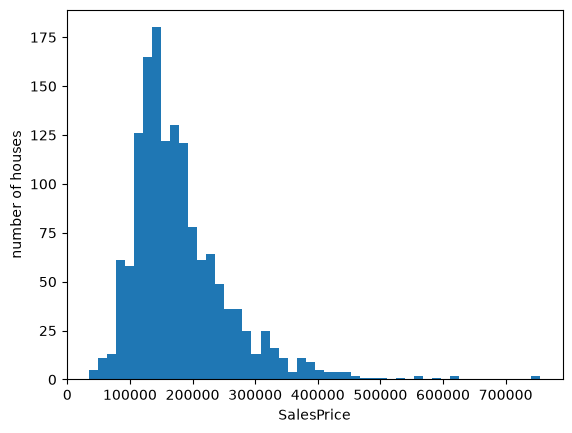

In [5]:
plt.hist(train["SalePrice"], bins=50)   # histogram of the price column
plt.xlabel("SalesPrice")
plt.ylabel("number of houses")
plt.show()
#our graph right skewed(a type of distribution where the long tail points to the right)

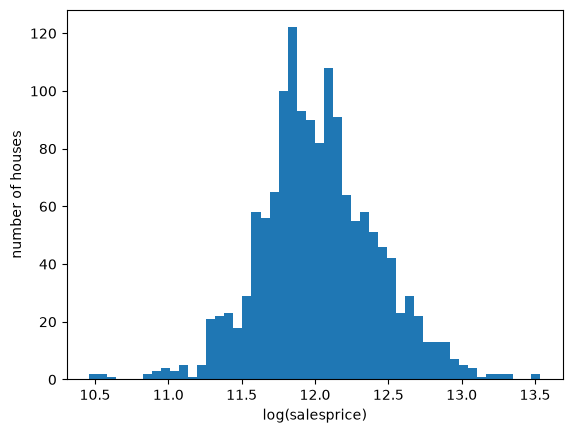

In [6]:
plt.hist(np.log1p(train["SalePrice"]),bins=50) #log1p=lpg(1+price)
#for every house; shrinks big prices more than small ones that's what the log does.
plt.xlabel("log(salesprice)")
plt.ylabel("number of houses")
plt.show()

## 2. Clean missing values


In [7]:

#fills the columns havng nan or na with none so the model can understand it better
col=["MiscFeature","Alley","PoolQC","Fence","MasVnrType","FireplaceQu",
    "BsmtExposure","BsmtFinType1","GarageType",
    "GarageCond","BsmtCond","BsmtQual","GarageQual","GarageFinish","BsmtFinType2"]
for cols in col:
    train[cols]=train[cols].fillna("none")

    


In [8]:
cnum_col=["GarageYrBlt","MasVnrArea"]
for co in cnum_col:
    train[co]=train[co].fillna(0)

In [9]:
neighbor_median = train.groupby("Neighborhood")["LotFrontage"].transform("median")
train["LotFrontage"] = train["LotFrontage"].fillna(neighbor_median)
common=train["Electrical"].mode()[0]
train["Electrical"]=train["Electrical"].fillna(common)


In [10]:
print("total missing: " ,train.isnull().sum().sum())  #cleaning is complete

total missing:  0


## 3. Feature engineering and encoding

In [11]:
# Total living space = basement + first floor + second floor (square feet)
train["TotalSF"] = train["TotalBsmtSF"] + train["1stFlrSF"] + train["2ndFlrSF"]

# House age when sold = year sold minus year built
train["HouseAge"] = train["YrSold"] - train["YearBuilt"]

# Years since last remodel (never remodeled = same as YearBuilt, so this equals HouseAge)
train["YearsSinceRemod"] = train["YrSold"] - train["YearRemodAdd"]
# Has a pool? (train["PoolArea"] > 0) gives True/False, .astype(int) turns that into 1/0
train["HasPool"] = (train["PoolArea"] > 0).astype(int)

In [12]:
# [[ ]] with two brackets = pick several columns at once
train[["TotalSF", "HouseAge", "YearsSinceRemod", "HasPool", "SalePrice"]].head()

,TotalSF,HouseAge,YearsSinceRemod,HasPool,SalePrice
0,2566,5,5,0,208500
1,2524,31,31,0,181500
2,2706,7,6,0,223500
3,2473,91,36,0,140000
4,3343,8,8,0,250000


In [13]:
# A dictionary: each text value -> a number (higher = better quality)
quality={"none":0,"Po":1,"Fa":2,"TA":3,"Gd":4,"Ex":5}
columns=["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
        "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
for co in columns:
        train[co]=train[co].map(quality)
        #.fillna() fixes empty cells
#.map() replaces every cell using a dictionary
print(train[columns].isnull().sum())

ExterQual      0
ExterCond      0
BsmtQual       0
BsmtCond       0
HeatingQC      0
KitchenQual    0
FireplaceQu    0
GarageQual     0
GarageCond     0
PoolQC         0
dtype: int64


In [14]:
train["MSSubClass"]=train["MSSubClass"].astype(str)
train_hotcode=pd.get_dummies(train,dtype=int)
print(train.shape)
print(train_hotcode.shape)
print(train.shape[0])
print(train_hotcode.shape[0])
print("text columns in train:", len(train.select_dtypes(exclude="number").columns))
# .nunique() = number of different values = number of new columns you'll get
print(train["Neighborhood"].nunique())
#unique values in that speccific column

(1460, 85)
(1460, 282)
1460
1460
text columns in train: 34
25


## 4. Train and compare models

In [15]:
y=np.log1p(train_hotcode["SalePrice"])
x=train_hotcode.drop(columns=["Id","SalePrice"])#drop these columns
print(x.shape)
print(y.shape)

(1460, 280)
(1460,)


In [16]:
from sklearn.model_selection import train_test_split
#to test the model later we are picking a test set of size=20% of data
# Split the 1460 houses into two groups:
#   80% to learn from  -> X_train, y_train
#   20% hidden for testing -> X_val, y_val
# random_state=42 makes the split identical every time you run it
x_train,x_value ,y_train,y_vaue=train_test_split(x,y,test_size=0.2,random_state=42)
#keep its sequence same
print(x_train.shape)
print(x_value.shape)

(1168, 280)
(292, 280)


In [17]:
# random_state=42 -> fixes the starting point (seed) of the random shuffle
#   - Computers don't do real randomness: a formula starts from a seed
#     and every number follows from the one before it.
#   - Same seed -> same shuffle -> the same 292 houses are hidden every run.
#   - No seed -> different houses hidden each run -> score changes by luck.
#   - Why it matters: when you add a feature and the score changes, you
#     know the FEATURE caused it, not the shuffle.
#   - 42 is just a popular joke number (Hitchhiker's Guide to the Galaxy).
#     Any number works. It does not make the model better or worse,
#     only repeatable.

In [18]:
from sklearn.ensemble import RandomForestRegressor
model=RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1)
model.fit(x_train,y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [19]:
from sklearn.metrics import root_mean_squared_error
prediction=model.predict(x_value)
print("RMS of random forest : " , root_mean_squared_error(y_vaue,prediction))


RMS of random forest :  0.14561787991106415


In [20]:
from sklearn.linear_model import LinearRegression,Ridge
lin=LinearRegression()
lin.fit(x_train,y_train)
print("linear RMS: " ,root_mean_squared_error(y_vaue,lin.predict(x_value)))
ridge = Ridge(alpha=10)    # linear regression with a brake on huge weights
ridge.fit(x_train, y_train)
print("Ridge RMSE:", root_mean_squared_error(y_vaue, ridge.predict(x_value)))


linear RMS:  0.12761568735042142
Ridge RMSE: 0.1333822972138995


In [21]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

lin_score=-cross_val_score(LinearRegression(),x,y,cv=5,scoring="neg_root_mean_squared_error")
print("linear: " ,lin_score.round(3), "average = " , lin_score.mean().round(4))
reg_score=-cross_val_score(Ridge(alpha=5),x,y,cv=5,scoring="neg_root_mean_squared_error" )
print("Ridge : " ,reg_score.round(3) , "average= " ,reg_score.mean().round(4))
fr_score=-cross_val_score(RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1),x,y,cv=5,scoring="neg_root_mean_squared_error")
print("forest: " ,fr_score.round(3),"average = ",fr_score.mean().round(4))






linear:  [0.14  0.163 0.164 0.116 0.196] average =  0.156
Ridge :  [0.118 0.148 0.133 0.119 0.182] average=  0.1399
forest:  [0.136 0.153 0.144 0.132 0.153] average =  0.1436


## 5. Tune Ridge alpha

In [22]:
#to find best alpha method 1: 
for a in [13,30,20,12]:
    reg_score=-cross_val_score(Ridge(alpha=a),x,y,cv=5,scoring="neg_root_mean_squared_error" )
    print("alpha =", a, "average =", reg_score.mean().round(4))


alpha = 13 average = 0.139
alpha = 30 average = 0.1393
alpha = 20 average = 0.139
alpha = 12 average = 0.139


In [23]:
#to find best alpha method 2 :
from sklearn.linear_model import RidgeCV
ridge_cv=RidgeCV(alphas=[0.1,1,50,70,32,19,13],cv=5)
ridge_cv.fit(x,y)
print("best alpha : "  ,ridge_cv.alpha_)

best alpha :  13.0


## 6. Remove outliers

In [24]:
# houses that are very big but sold cheap
#An outlier is a data point that’s very different from the rest. In your data,
#  it’s a house that doesn’t follow the normal pattern.
print(train[(train["GrLivArea"]>4000) & (train["SalePrice"]<300000)][["GrLivArea", "SalePrice"]])
keep=~((train["GrLivArea"]>4000) & (train["SalePrice"]<300000))
xk=x[keep]
yk=y[keep]
score=-cross_val_score(Ridge(alpha=13),xk,yk,cv=5,scoring="neg_root_mean_squared_error")
print("ridge without outlier" , score.mean().round(4))


      GrLivArea  SalePrice
523        4676     184750
1298       5642     160000
ridge without outlier 0.1145


## 7. Prepare test data

In [25]:
test=pd.read_csv("test.csv")
print(test.shape)
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
            "GarageType", "GarageFinish", "GarageQual", "GarageCond",
            "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
            "MasVnrType"]
for col in none_cols:
    test[col]=test[col].fillna("none")
# LotFrontage: median of the house's own neighborhood, same as train
nb_median = test.groupby("Neighborhood")["LotFrontage"].transform("median")
test["LotFrontage"] = test["LotFrontage"].fillna(nb_median)
# test has a few extra empty cells that train didn't:
# number columns -> 0, text columns -> most common value


(1459, 80)


In [26]:
for col in test.columns:
    if test[col].isnull().sum()>0:
        if pd.api.types.is_numeric_dtype(test[col]):
            test[col]=test[col].fillna(0)
        else :
            test[col]=test[col].fillna(test[col].mode()[0])
print("missing : " , test.isnull().sum().sum())
print((test["LotFrontage"] == 0).sum())    # should print 0

missing :  0
0


In [27]:
test["TotalSF"] = test["TotalBsmtSF"] + test["1stFlrSF"] + test["2ndFlrSF"]
test["HouseAge"] = test["YrSold"] - test["YearBuilt"]
test["YearsSinceRemod"] = test["YrSold"] - test["YearRemodAdd"]
test["HasPool"] = (test["PoolArea"] > 0).astype(int)

# quality text -> numbers, using your same `quality` dictionary
quality_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
                "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
for col in quality_cols:
    test[col] = test[col].map(quality)

test["MSSubClass"] = test["MSSubClass"].astype(str)

print("missing after map:", test[quality_cols].isnull().sum().sum())   # should be 0
print(test.shape)                                                      # (1459, 85)

missing after map: 0
(1459, 84)


In [28]:
#you get 1/0 and not True/False.
test_encoded = pd.get_dummies(test, dtype=int)
test_encoded = test_encoded.reindex(columns=x.columns, fill_value=0)
print(test_encoded.shape)                 # (1459, 280)
print(x.shape)                            # (1460, 280)
print(test_encoded.isnull().sum().sum())  # 0
print([c for c in x.columns if c.startswith("Alley_")])
print([c for c in test_encoded.columns if c.startswith("Alley_")])   # same list as the line above

(1459, 280)
(1460, 280)
0
['Alley_Grvl', 'Alley_Pave', 'Alley_none']
['Alley_Grvl', 'Alley_Pave', 'Alley_none']


## 8. Final model and submission

In [29]:
final = Ridge(alpha=13)
final.fit(xk, yk)
prediction = final.predict(test_encoded)# log scale (about 12.1)
pred_price = np.expm1(prediction) # convert back to dollars (about 180000)
print(pred_price[:5])    # should look like 120000, 150000, 180000, not 12.1

[115813.21982244 155829.44357123 178077.99202716 199018.44811668
 193997.7915801 ]


In [30]:
submission = pd.DataFrame({"Id": test["Id"], "SalePrice": pred_price})
submission.to_csv("submission.csv", index=False)
print(submission.shape)      # (1459, 2)
print(submission.head())


(1459, 2)
     Id      SalePrice
0  1461  115813.219822
1  1462  155829.443571
2  1463  178077.992027
3  1464  199018.448117
4  1465  193997.791580


In [31]:
print(submission.shape)              # (1459, 2)
print(submission.head())             # Id starts at 1461
print(submission["SalePrice"].min(), submission["SalePrice"].max())

(1459, 2)
     Id      SalePrice
0  1461  115813.219822
1  1462  155829.443571
2  1463  178077.992027
3  1464  199018.448117
4  1465  193997.791580
45698.69828786959 1742041.8799954047


## 9. Fixing one bad prediction (Id 2550)

In [32]:
i = submission["SalePrice"].idxmax()     # row number of the highest prediction
print(test.loc[i, ["Id", "GrLivArea", "TotalSF", "LotArea", "YearBuilt", "GarageYrBlt", "OverallQual", "Neighborhood"]])

# compare with the biggest values in train
print(train[["GrLivArea", "TotalSF", "LotArea", "YearBuilt", "GarageYrBlt"]].max())
print((submission["SalePrice"] > 600000).sum())


Id                 2550
GrLivArea          5095
TotalSF         10190.0
LotArea           39290
YearBuilt          2008
GarageYrBlt      2008.0
OverallQual          10
Neighborhood    Edwards
Name: 1089, dtype: object
GrLivArea        5642.0
TotalSF         11752.0
LotArea        215245.0
YearBuilt        2010.0
GarageYrBlt      2010.0
dtype: float64
1


In [33]:
print(test.loc[i, "SaleCondition"])
cap = train["SalePrice"].max()                  # 755000
pred_capped = np.clip(pred_price, None, cap)    # nothing above the cap

submission = pd.DataFrame({"Id": test["Id"], "SalePrice": pred_capped})
submission.to_csv("submission.csv", index=False)

print(submission["SalePrice"].max())            # should be 755000 at most

Partial
755000.0


In [35]:
partial_median = train.loc[train["SaleCondition"] == "Partial", "SalePrice"].median()
pred_v2 = pred_capped.copy()
pred_v2[test["Id"] == 2550] = partial_median
pd.DataFrame({"Id": test["Id"], "SalePrice": pred_v2}).to_csv("submission_v2.csv", index=False)